# *Tests for Density Analysis Methods*

Kernel Estimation, Ripleys K function, Nearest Neighbors

In [1]:
import os
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append("../")
from analysis.density_methods import SpineDensity as sd

%load_ext autoreload
%autoreload 2

In [2]:
data_dir = "C:\\Users\\brogab\\Documents\\spines\\data\\comp_brian\\CSV_spines"

In [3]:
os.listdir(data_dir)

['Lightning 001Oblique1_Lng_spines.csv',
 'Lightning 002_MainApical1_Lng_spines.csv',
 'Lightning 003_Tuft1_Lng_spines.csv',
 'Lightning 004_Tuft1_Lng_spines.csv']

In [4]:
obl1 = pd.read_csv(os.path.join(data_dir, 'Lightning 001Oblique1_Lng_spines.csv'))
obl1.head()

,ID,SECTION-NUMBER,SECTION-LENGTH,BRANCH-ORDER,RAYBURST-VOLUME,NON-ATTACH-SA,X,Y,Z,HEAD-DIAMETER,...,MAX-DTS,TYPE,AUTO,XYPLANE-ANGLE,SWC-NODE-ID,SWC-NODE-OFFSET,ATTACH-X,ATTACH-Y,ATTACH-Z,SOMA-DISTANCE
0,20,0,41.438396,NaN,0.864466,6.135283,34.848038,20.175327,5.475138,0.580760,...,2.161775,mushroom,yes,68.623043,97,0.0,34.206104,20.469563,7.279165,36.664646
1,26,0,41.438396,NaN,0.032299,0.553776,30.190857,20.253418,4.219728,0.264558,...,2.054399,thin,yes,85.433614,85,0.0,30.216919,20.439192,6.568526,31.517948
2,28,0,41.438396,NaN,0.199526,1.924669,1.577570,12.021452,2.836537,0.430510,...,1.925469,mushroom,yes,4.259670,4,0.0,1.661347,14.010247,2.984799,1.243300
3,30,0,41.438396,NaN,0.672676,4.291018,11.842226,13.409301,3.331609,0.768083,...,1.794177,mushroom,yes,41.430899,30,0.0,11.851035,14.570062,4.356100,11.871390
4,31,0,41.438396,NaN,0.405092,3.073693,31.240519,21.188101,5.215016,0.644852,...,1.773795,mushroom,yes,51.830135,89,0.0,30.678320,20.274363,6.579829,33.335506


In [5]:
spine_locs = obl1.loc[:, "SOMA-DISTANCE"].to_numpy()

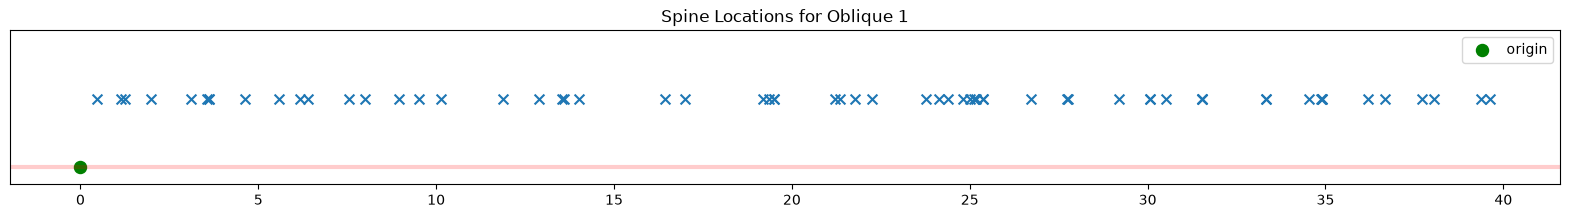

In [6]:
# view spine locations along branch
fig = plt.figure(figsize = (20, 2))

# set up branch graph
plt.axhline(y=0, color='r', linestyle='-', linewidth = 3.0, alpha = 0.2)
plt.scatter(0, 0, marker='o', color='g', s = 75, label='origin')
plt.ylim(-0.25, 2)
plt.yticks([])

# plot the spines
plt.scatter(spine_locs, np.ones(spine_locs.shape), marker = 'x', s = 50)

plt.legend()
plt.title("Spine Locations for Oblique 1")
plt.show()

## **Nearest Neighbor Analyses**

### *Average Nearest Neighbors*

In [7]:
# calculate the average of the nearest neighbors for spine locations
avg_nn_spines, dist_arr = sd.avg_nn_1D(spine_locs)

print('Nearest Neighbors Metrics')
print(f'    AVG : {avg_nn_spines}')
print(f'    MAX : {np.max(dist_arr)}')
print(f'    MIN : {np.min(dist_arr)}')
print(f'    VAR : {np.var(dist_arr)}')
print(f'    STD : {np.std(dist_arr)}')

Nearest Neighbors Metrics
    AVG : 0.3884408571428573
    MAX : 1.204155
    MIN : 0.006648999999999461
    VAR : 0.10820605223021752
    STD : 0.32894688360009966


## **Clustering**

### *DBSCAN*

Applying the DBSCAN algorithm to the 1-dimensional array of spine locations (distances from the origin in neuron studio along the labeled branch)

Uses the following params:

- `eps` (epsilon : `float`) The maximum distance between two objects to be considered neighbors. Default is 0.5
- `min_pts` (minimum points : `int`) The minimum number of points within `eps` to determine "core point", or cluster. Default is 2

Notes:

Could have some kind of optimization plot for eps and min_pts

In [8]:
# DBSCAN (SKLearn)
eps = .5
min_pts = 2

dbscan = sd.dbscan(spine_locs, eps, min_pts)
c2p_ratio = np.unique(dbscan).shape[0] / spine_locs.shape[0]
print(f'# of clusters found {np.max(dbscan) + 1}')
print(f'Cluster to Spine ratio: {c2p_ratio:.2f}')

# of clusters found 16
Cluster to Spine ratio: 0.27


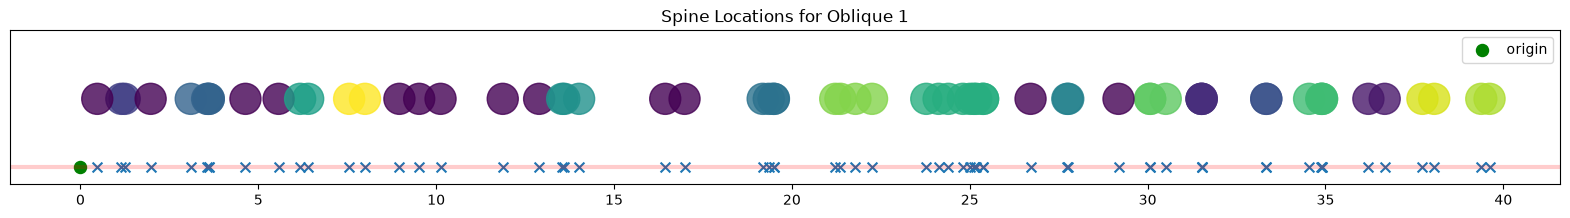

In [9]:
# plot dbscan clusters
fig = plt.figure(figsize = (20, 2))

# set up branch graph
plt.axhline(y=0, color='r', linestyle='-', linewidth = 3.0, alpha = 0.2)
plt.scatter(0, 0, marker='o', color='g', s = 75, label='origin')
plt.ylim(-0.25, 2)
plt.yticks([])

# plot the clustered spines
plt.scatter(spine_locs, np.ones(spine_locs.shape), marker = 'o', s = 500, c = dbscan, alpha = 0.8)
plt.scatter(spine_locs, np.full(spine_locs.shape, 0.0), marker = 'x', s = 50)

plt.legend()
plt.title("Spine Locations for Oblique 1")
plt.show()

### *Ripley's K-Function*

Applies Ripley's K-Function clustering method to the 1-Dimensional spine location array.

Uses the following params:

- `L` (length : int) length of the analyzed domain, i.e. branch length
- `r` (radius : float) radius of clustering 

Notes:

In [82]:
length = obl1.loc[0, 'SECTION-LENGTH']
radii = np.linspace(1e-6,10, 100)
k_random = 2.0 * radii
k_observed = np.array([sd.ripley_kfunc_1D(spine_locs, length, r) for r in radii])

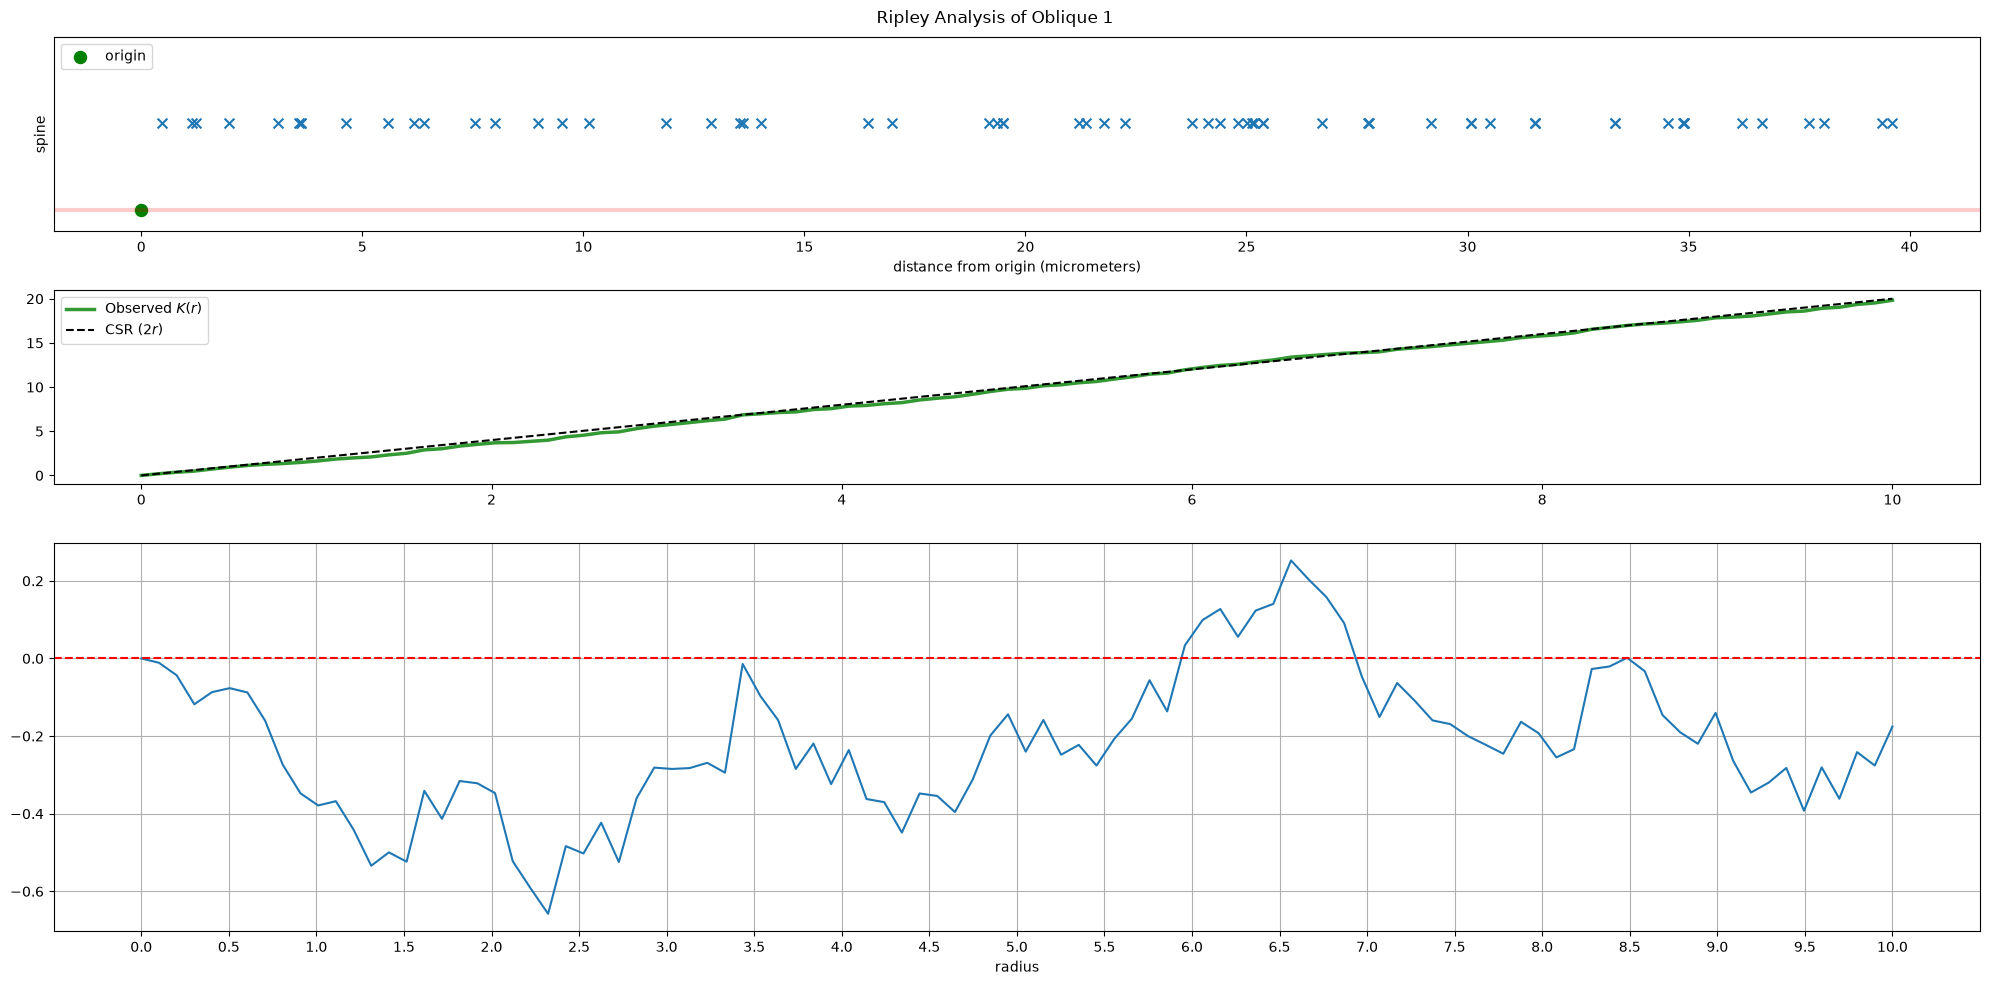

In [87]:
fig, axes = plt.subplots(3, 1, figsize = (20, 10), sharex=False, height_ratios=[1, 1, 2])

axes[0].axhline(y=0, color='r', linestyle='-', linewidth = 3.0, alpha = 0.2)
axes[0].scatter(0, 0, marker='o', color='g', s = 75, label='origin')
axes[0].set_ylim(-0.25, 2)
axes[0].set_yticks([])
axes[0].scatter(spine_locs, np.ones(spine_locs.shape), marker = 'x', s = 50)
axes[0].set_ylabel("spine")
axes[0].set_xlabel("distance from origin (micrometers)")
axes[0].legend(loc='upper left')

axes[1].plot(radii, k_observed, label='Observed $K(r)$', color='green', linewidth=2.5, alpha = 0.8)
axes[1].plot(radii, k_random, label='CSR ($2r$)', color='black', linestyle='--')
# axes[1].scatter(spine_locs, np.full(spine_locs.shape, 0.0), marker = 'x', s = 50)
axes[1].legend()

axes[2].plot(radii, k_observed - k_random)
axes[2].axhline(y=0.0, linestyle='--', color = 'red')
axes[2].set_xlabel("radius")
axes[2].set_xticks(np.linspace(0, 10, 21))
axes[2].grid()


fig.suptitle("Ripley Analysis of Oblique 1")
plt.tight_layout()
plt.show()

In [34]:
# fake ripleys test

cluster_begin = 2
cluster_end = 4
cluster_density = 50

fake_data = np.concat([
    np.array([1]),
    np.linspace(cluster_begin, cluster_end, cluster_density),
    np.arange(cluster_end, 10)
])

fake_length = max(fake_data)
fake_radii = np.linspace(1e-6, fake_length, round(fake_length))
fake_k_random = 2.0 * fake_radii
fake_k_observed = np.array([sd.ripley_kfunc_1D(fake_data, fake_length, r) for r in fake_radii])

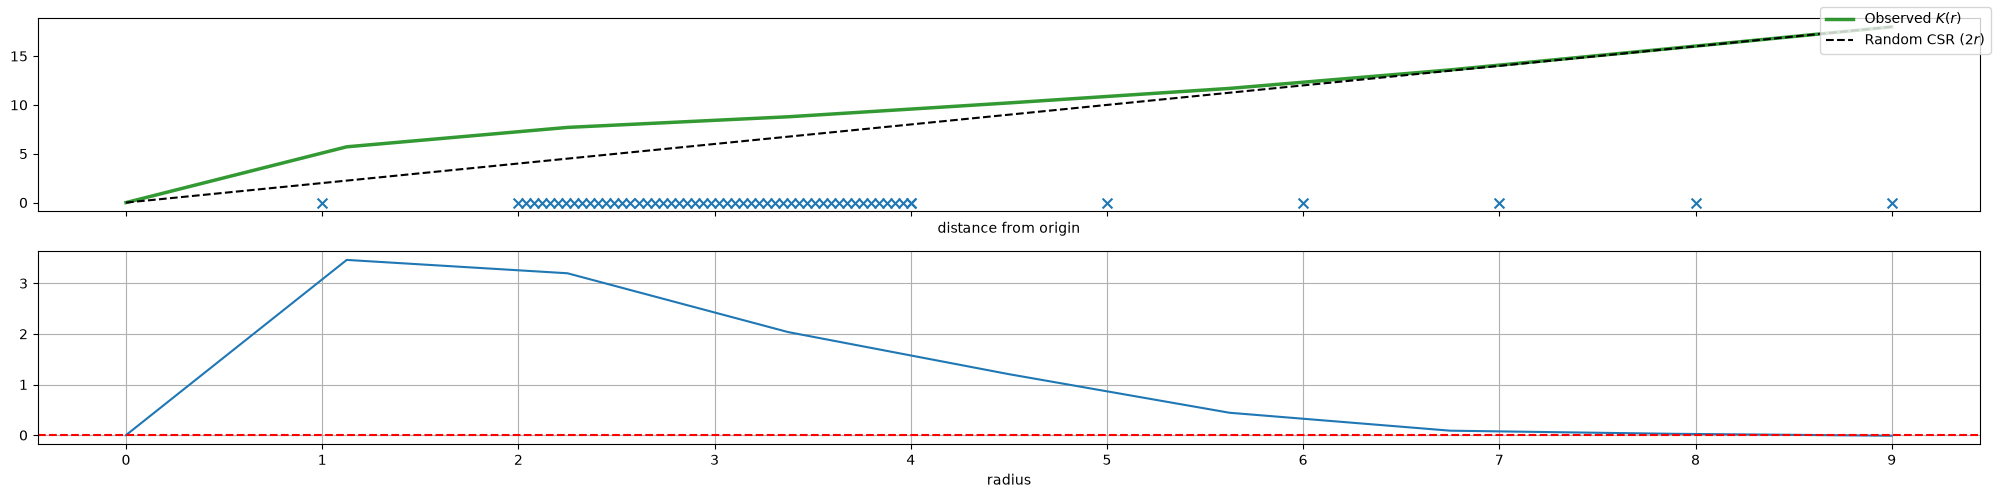

In [35]:
fig, axes = plt.subplots(2, 1, figsize = (20, 5), sharex=True)

axes[0].plot(fake_radii, fake_k_observed, label='Observed $K(r)$', color='green', linewidth=2.5, alpha = 0.8)
axes[0].plot(fake_radii, fake_k_random, label='Random CSR ($2r$)', color='black', linestyle='--')
axes[0].scatter(fake_data, np.full(fake_data.shape, 0.0), marker = 'x', s = 50)
axes[0].set_xlabel("distance from origin")

axes[1].plot(fake_radii, fake_k_observed - fake_k_random)
axes[1].axhline(y=0.0, linestyle='--', color = 'red')
axes[1].set_xlabel("radius")
axes[1].set_xticks(np.linspace(0, fake_length, int(fake_length+1)))
axes[1].grid()

fig.legend()
plt.tight_layout()
plt.show()

## **Kernel Density Estimation**

### *Gaussian KDE (Scipy)*

Applies Scipy's gaussian kernel density estimation method to the 1-Dimensional spine location array. By default, Scipy uses *Scott's factor* for bandwidth selection

Uses the following params:

- `eval_buff` (evaluation buffer : `int`) specifies the size of the buffer to apply to the spine location array during the convolution. Default is 2
- `eval_sf` (evaluation size factor : `float`) specifies the factor applied to resolution of the evaluation grid after the gaussian density estimation is initialized. Default is 1.0

Notes:

Bandwidth selection needs implementation


In [71]:
bandwidth = 0.1
eval_buff = 1
eval_sf = 10.0

eval_grid, spine_gauss_kde = sd.gaussian_kde_1D(spine_locs, bandwidth = bandwidth, eval_buff = eval_buff, eval_sf = eval_sf)

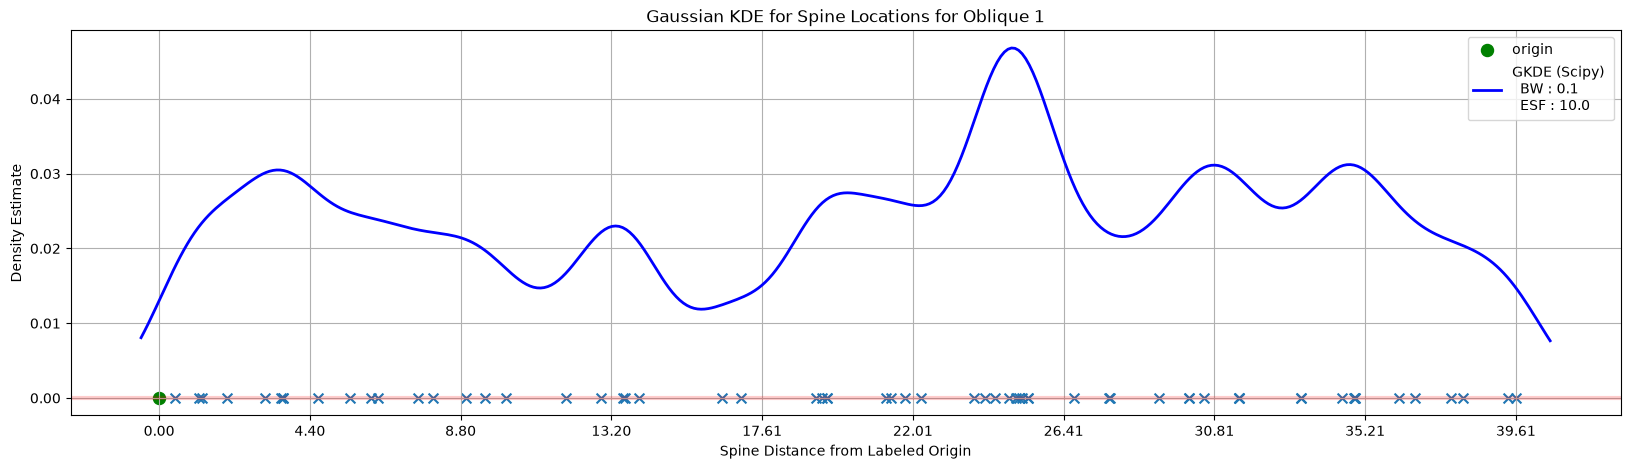

In [72]:
# plot gaussian kernel density estimation
fig = plt.figure(figsize = (20, 5))

# set up branch graph
plt.axhline(y=0, color='r', linestyle='-', linewidth = 3.0, alpha = 0.2)
plt.scatter(0, 0, marker='o', color='g', s = 75, label='origin')
ylim_buff = 0.05 * np.max(spine_gauss_kde)
plt.ylim(0 - ylim_buff, np.max(spine_gauss_kde) + ylim_buff)
plt.ylabel('Density Estimate')
plt.xlabel('Spine Distance from Labeled Origin')
plt.xticks(np.linspace(0, np.max(spine_locs), 10))

# plot the Gaussian KDE spines
# plt.plot(np.linspace(np.min(spine_locs), np.max(spine_locs), spine_gauss_kde.shape[0]), spine_gauss_kde, c = 'blue', linewidth = 2, label = f'GKDE (Scipy) BW : {bandwidth}')
plt.plot(eval_grid, spine_gauss_kde, c = 'blue', linewidth = 2, label = f'GKDE (Scipy) \n  BW : {bandwidth} \n  ESF : {eval_sf}')
plt.scatter(spine_locs, np.full(spine_locs.shape, 0.0), marker = 'x', s = 50)

plt.legend()
plt.grid()
plt.title("Gaussian KDE for Spine Locations for Oblique 1")
plt.show()